Dataset shape: (442, 10)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
MAE: 47.04539158640984
RMSE: 59.74081738077601
R2 Score: 0.3263754171777956


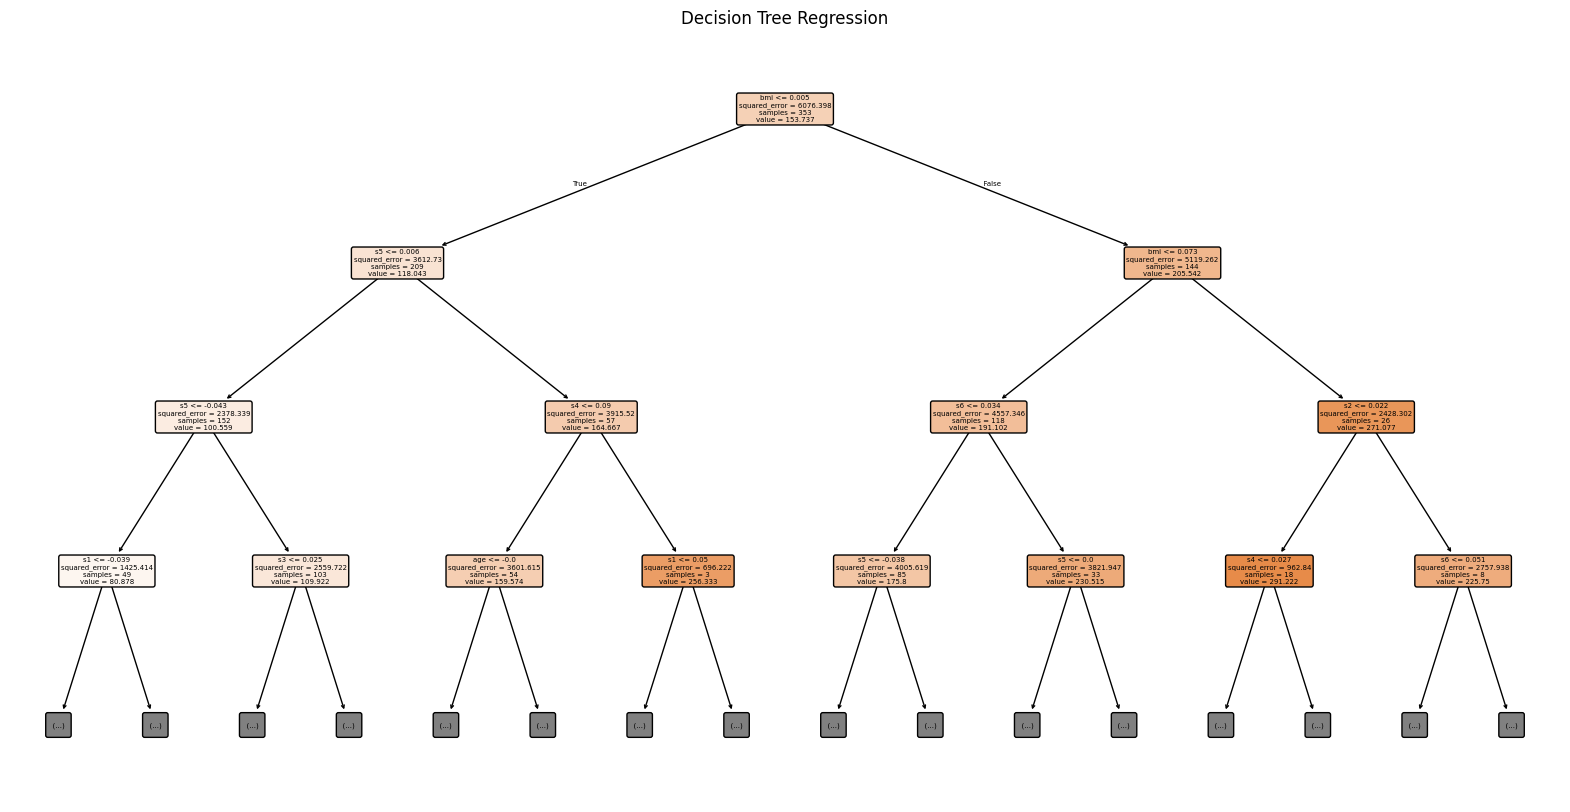

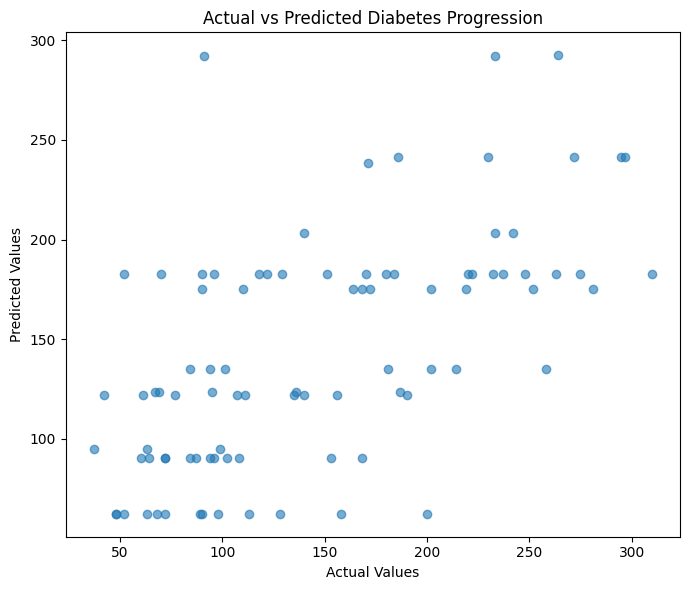

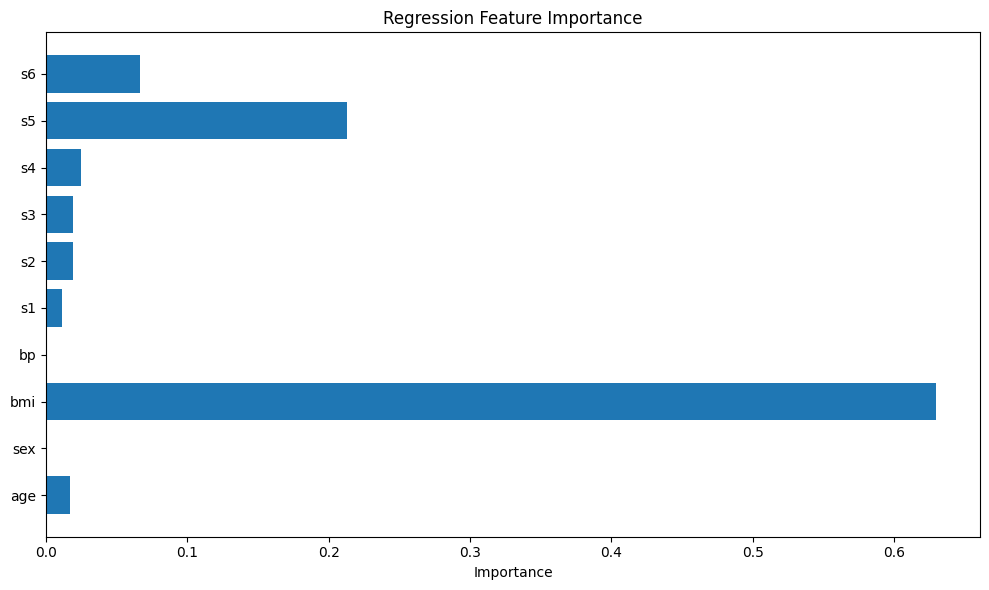

In [1]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load dataset
data = load_diabetes(as_frame=True)

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Features:", X.columns.tolist())

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train model
# Regression trees do not support criterion="entropy"
model = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))

print(
    "RMSE:",
    mean_squared_error(y_test, y_pred) ** 0.5
)

print("R2 Score:", r2_score(y_test, y_pred))

# Visualize decision tree
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title("Decision Tree Regression")
plt.show()

# Actual vs predicted values
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Diabetes Progression")

plt.tight_layout()
plt.show()

# Feature importance
plt.figure(figsize=(10, 6))

plt.barh(X.columns, model.feature_importances_)

plt.xlabel("Importance")
plt.title("Regression Feature Importance")

plt.tight_layout()
plt.show()

In [2]:
%pip install dtreeviz

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names


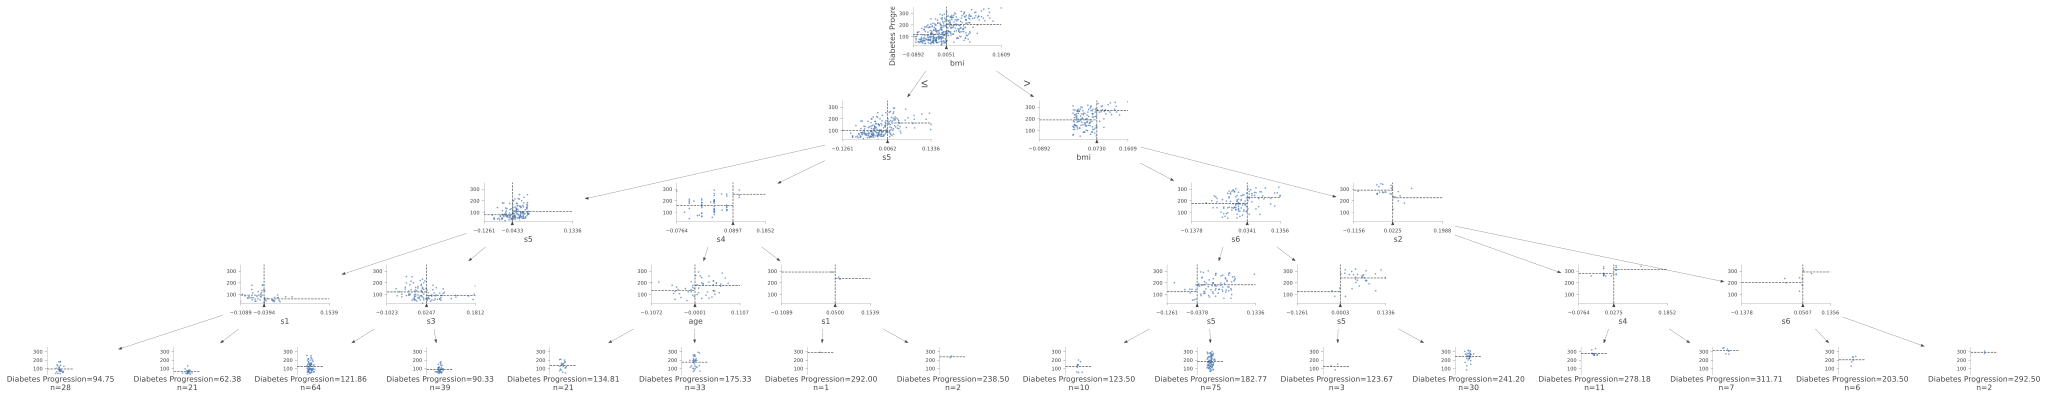

In [3]:
import dtreeviz
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

# Load dataset
data = load_diabetes(as_frame=True)

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train Decision Tree
regressor = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=4,
    random_state=42
)

regressor.fit(X_train, y_train)

# dtreeviz visualization
viz = dtreeviz.model(
    regressor,
    X_train=X_train,
    y_train=y_train,
    feature_names=X.columns.tolist(),
    target_name="Diabetes Progression"
)

# Display tree
viz.view()